# MediConnect: previsão do não comparecimento a consultas médicas

**Centro Universitário Assis Gurgacz** – Engenharia de Software
Disciplina: Mineração de Dados
Aluno: Arthur Stempniak
Professor: Pedro Henrique De Avila Tonin
Cascavel, 2026

Este notebook traz a parte prática do artigo *MediConnect: previsão do não comparecimento a consultas médicas*, que está na pasta `docs/`. O trabalho segue as etapas do CRISP-DM: entendimento do negócio, entendimento dos dados, preparação, modelagem e avaliação. A implantação ficou apenas como proposta, porque a base é de outro município e de 2016.

As funções usadas aqui ficam na pasta `src/`. O mesmo processo pode ser rodado de uma vez com o script `executar_analise.py`, que também grava as figuras e as tabelas. Neste notebook as etapas são executadas uma a uma, com um comentário sobre cada resultado.

In [1]:
import sys
from pathlib import Path

# Permite importar a pasta src/ rodando o notebook de dentro de notebook/ ou da raiz do projeto
RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import pandas as pd

from src import avaliacao, dados, exploracao, graficos, modelagem
from src.config import ATRIBUTOS_A, ATRIBUTOS_B
from src.exploracao import pct

graficos.configurar_estilo()

## 1. Entendimento do negócio

Quando um paciente falta, o horário fica vazio e poderia ter sido usado por outra pessoa. As faltas também atrapalham a previsão da demanda e o planejamento das equipes.

No MediConnect, a ideia é estimar o risco de falta no momento do agendamento e usar essa estimativa para decidir a quem mandar um lembrete a mais ou um pedido de confirmação. O modelo não serve para diagnosticar pacientes nem para decidir quem será atendido.

Como o MediConnect ainda não tem um histórico próprio de agendamentos, foi usada a base pública *Medical Appointment No Shows* (Hoppen, Kaggle). Por isso os resultados valem como prova de conceito do método, e não como retrato dos pacientes da plataforma.

## 2. Entendimento dos dados

In [2]:
bruto = dados.carregar_base()
dados.resumo_base(bruto)

{'linhas': 110527,
 'colunas': 14,
 'pacientes': 62299,
 'bairros': 81,
 'agendamento_min': '2015-11-10',
 'agendamento_max': '2016-06-08',
 'consulta_min': '2016-04-29',
 'consulta_max': '2016-06-08',
 'consulta_tem_horario': False,
 'valores_handcap': {0: 108286, 1: 2042, 2: 183, 3: 13, 4: 3}}

In [3]:
bruto.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


Cada linha da base é uma consulta, e não uma pessoa. Isso faz diferença mais adiante: o mesmo paciente pode ter várias consultas, e todas elas precisam ficar do mesmo lado quando os dados forem divididos entre treino e teste.

### 2.1 Qualidade dos dados

In [4]:
dados.verificar_qualidade(bruto)

,Verificação,Quantidade,Tratamento
0,Valores ausentes,0,Nenhuma imputação necessária
1,Linhas duplicadas completas,0,Nenhuma remoção
2,AppointmentID repetido,0,Nenhuma remoção
3,Duplicadas sem AppointmentID,618,Mantidas como consultas distintas
4,Pacientes com mais de uma consulta,24379,Mantidos; agrupados na validação
5,Consultas desses pacientes,72607,Mantidas
6,Idade negativa,1,Removida
7,Idade igual a zero,3539,Mantida
8,Idade acima de 100 anos,7,Mantida e registrada como possível anomalia
9,Consultas anteriores ao agendamento,5,Removidas


Não há valores ausentes nem linhas repetidas por inteiro. As 618 linhas que ficam iguais quando se ignora o `AppointmentID` foram mantidas, porque são consultas com identificadores diferentes e não cópias do mesmo registro.

Seis registros são impossíveis do ponto de vista lógico: uma idade negativa e cinco consultas marcadas para antes da data em que foram agendadas. Esses foram os únicos removidos.

In [5]:
dados.registros_invalidos(bruto)

,AppointmentID,ScheduledDay,AppointmentDay,Age,WaitingDays,No-show,Motivo
27033,5679978,2016-05-10T10:51:53Z,2016-05-09T00:00:00Z,38,-1,Yes,Consulta anterior ao agendamento
55226,5715660,2016-05-18T14:50:41Z,2016-05-17T00:00:00Z,19,-1,Yes,Consulta anterior ao agendamento
64175,5664962,2016-05-05T13:43:58Z,2016-05-04T00:00:00Z,22,-1,Yes,Consulta anterior ao agendamento
71533,5686628,2016-05-11T13:49:20Z,2016-05-05T00:00:00Z,81,-6,Yes,Consulta anterior ao agendamento
72362,5655637,2016-05-04T06:50:57Z,2016-05-03T00:00:00Z,7,-1,Yes,Consulta anterior ao agendamento
99832,5775010,2016-06-06T08:58:13Z,2016-06-06T00:00:00Z,-1,0,No,Idade negativa (-1)


## 3. Preparação dos dados

Depois de remover os seis registros, foram criadas três variáveis:

- `NoShow`: 1 quando o paciente faltou e 0 quando compareceu (é a variável-alvo);
- `Gender_M`: 1 para masculino e 0 para feminino;
- `WaitingDays`: dias entre o agendamento e a consulta, sendo 0 uma consulta no mesmo dia.

A idade zero foi mantida, porque pode ser consulta de bebê. As sete idades acima de 100 anos e os códigos 2 a 4 de `Handcap` também ficaram, já que a documentação da base não diz que sejam inválidos. As faixas de idade e de espera servem só para as tabelas e gráficos; os modelos recebem os valores contínuos.

In [6]:
df = dados.preparar_dados(bruto)
taxa_geral = df["NoShow"].mean()

print("Consultas após a limpeza:", len(df))
print("Pacientes após a limpeza:", df["PatientId"].nunique())
print("Faltas:", int(df["NoShow"].sum()), f"({pct(taxa_geral)})")

Consultas após a limpeza: 110521
Pacientes após a limpeza: 62298
Faltas: 22314 (20,2%)


## 4. Análise exploratória

A taxa de falta de um grupo é o número de faltas dividido pelo número de consultas daquele grupo.

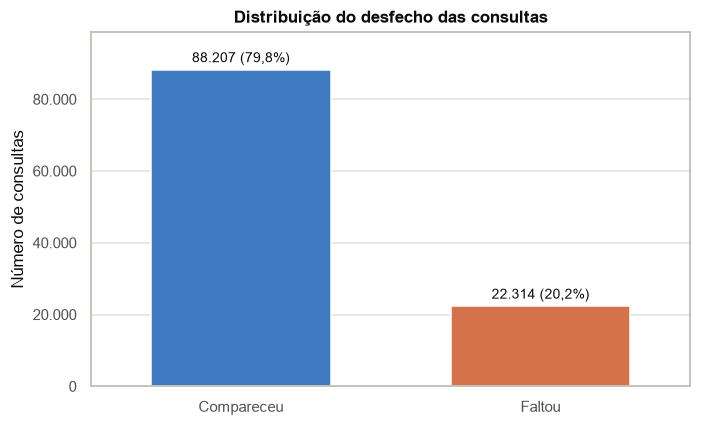

In [7]:
graficos.grafico_desfecho(df)
plt.show()

Cerca de uma em cada cinco consultas terminou em falta. Com essa proporção, um modelo que sempre responde "vai comparecer" já acerta quase 80% das vezes, sem identificar nenhuma falta. Por isso a acurácia sozinha não serve para comparar os modelos, e a avaliação usa precisão, recall, F1-score e ROC-AUC.

### 4.1 Tempo de espera (H1)

,consultas,faltas,taxa
FaixaEspera,,,
0,38562,1792,"4,6%"
1–3,14675,3359,"22,9%"
4–7,17510,4413,"25,2%"
8–14,12025,3664,"30,5%"
15–30,17371,5661,"32,6%"
31–60,8283,2829,"34,2%"
61+,2095,596,"28,4%"


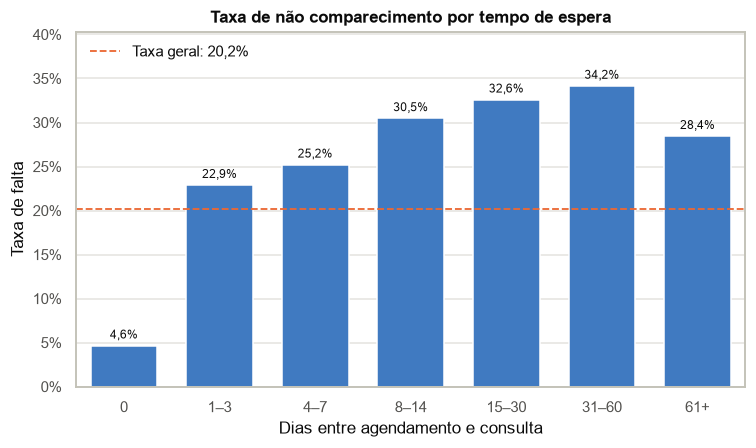

In [8]:
por_espera = exploracao.taxa_por(df, "FaixaEspera")
display(por_espera.style.format({"taxa": pct}))

graficos.grafico_taxa(por_espera, taxa_geral, "Taxa de não comparecimento por tempo de espera",
                      "Dias entre agendamento e consulta")
plt.show()

O tempo de espera foi o atributo com a relação mais clara com a falta. Nas consultas do mesmo dia a taxa é de apenas 4,6%, e ela sobe nas faixas seguintes até 34,2% entre 31 e 60 dias. Na faixa de 61 dias ou mais cai para 28,4%, mas continua acima da média. O resultado apoia a H1, mesmo sem ser perfeitamente crescente.

A base é observacional, então não dá para saber o motivo. Pode ser esquecimento, mudança na rotina ou a pessoa ter melhorado e não precisar mais da consulta. O que se tem é um padrão, não uma prova de que esperar mais causa falta.

### 4.2 Idade (H3)

,consultas,faltas,taxa
FaixaIdade,,,
0–12,21035,4306,"20,5%"
13–18,7830,2040,"26,1%"
19–30,16763,4141,"24,7%"
31–45,21953,4691,"21,4%"
46–60,23179,4131,"17,8%"
61–75,14370,2136,"14,9%"
76+,5391,869,"16,1%"


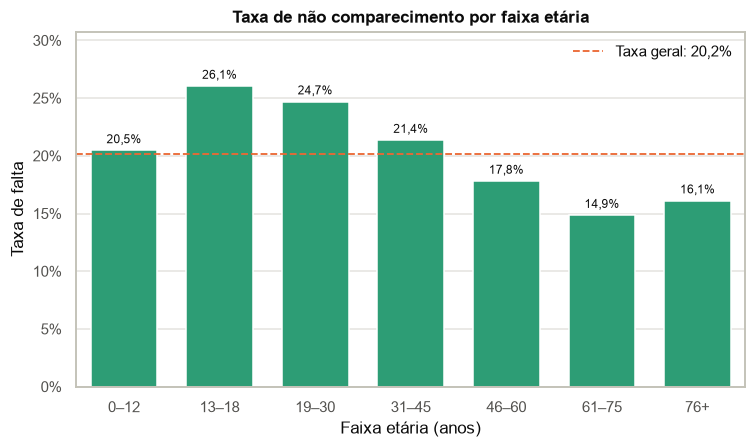

In [9]:
por_idade = exploracao.taxa_por(df, "FaixaIdade")
display(por_idade.style.format({"taxa": pct}))

graficos.grafico_taxa(por_idade, taxa_geral, "Taxa de não comparecimento por faixa etária",
                      "Faixa etária (anos)", cor=graficos.VERDE, posicao_legenda="upper right")
plt.show()

As maiores taxas aparecem entre 13 e 18 anos (26,1%) e entre 19 e 30 anos (24,7%). A menor fica entre 61 e 75 anos (14,9%). A H3 tem apoio descritivo. A idade provavelmente funciona como marcador de outras coisas que a base não mostra, como rotina de trabalho, dependência de acompanhante ou facilidade de deslocamento.

### 4.3 SMS e tempo de espera (H2)

In [10]:
exploracao.resumo_sms(df)

{'taxa_geral': {0: 0.16697983715134795, 1: 0.27574544839637},
 'menor_espera_com_sms': 3,
 'consultas_mesmo_dia_com_sms': 0,
 'taxa_espera_3_dias_ou_mais': {0: 0.3269489384245487, 1: 0.27574544839637},
 'consultas_espera_3_dias_ou_mais': 60021}

,consultas_sem_sms,taxa_sem_sms,consultas_com_sms,taxa_com_sms
FaixaEspera,,,,
0,38562,"4,6%",0,-
1–3,13769,"23,0%",906,"21,3%"
4–7,6868,"27,1%",10642,"24,0%"
8–14,5021,"33,8%",7004,"28,1%"
15–30,6851,"36,9%",10520,"29,8%"
31–60,3224,"38,4%",5059,"31,5%"
61+,744,"33,9%",1351,"25,5%"


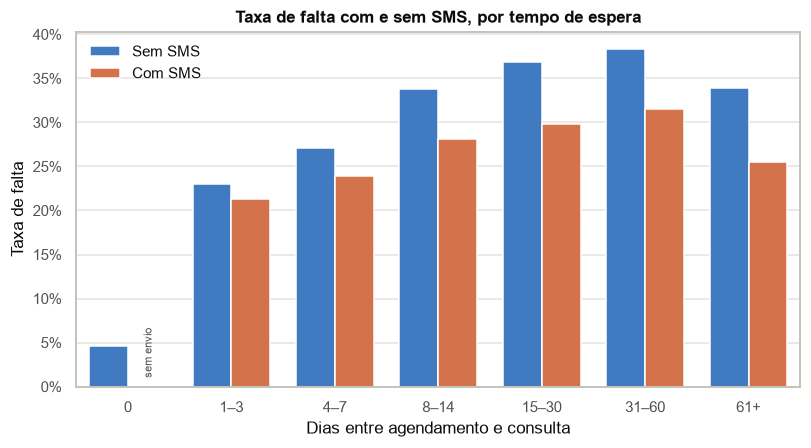

In [11]:
sms_espera = exploracao.sms_por_espera(df)
display(sms_espera.style.format({"taxa_sem_sms": pct, "taxa_com_sms": lambda v: "-" if pd.isna(v) else pct(v)}))

graficos.grafico_sms_por_espera(sms_espera)
plt.show()

Olhando só o total, quem recebeu SMS faltou mais (27,6% contra 16,7%). Isso não quer dizer que a mensagem aumente as faltas. Nenhuma consulta do mesmo dia recebeu SMS, e o envio só aparece a partir de três dias de espera. Ou seja, o grupo sem SMS concentra justamente as consultas que quase nunca têm falta.

Comparando dentro de cada faixa de espera, a taxa com SMS fica abaixo da taxa sem SMS em todas as faixas em que existem os dois grupos. Mesmo assim, a base não informa quando nem por qual critério o SMS foi enviado, então não é possível falar em efeito causal.

### 4.4 Sexo, Bolsa Família e condições de saúde (H4)

In [12]:
assoc = exploracao.associacoes(df)
assoc.style.format({"Taxa com": pct, "Taxa sem": pct, "Qui-quadrado": "{:.1f}",
                    "p-valor": "{:.2g}", "V de Cramér": "{:.3f}"})

,Atributo,Consultas com o atributo,Taxa com,Taxa sem,Qui-quadrado,p-valor,V de Cramér
0,Sexo masculino,38685,"20,0%","20,3%",1.9,0.17,0.004
1,Bolsa Família,10861,"23,7%","19,8%",93.8,3.5e-22,0.029
2,Hipertensão,21801,"17,3%","20,9%",140.3,2.2e-32,0.036
3,Diabetes,7943,"18,0%","20,4%",25.2,5e-07,0.015
4,Alcoolismo,3360,"20,1%","20,2%",0.0,0.97,0.000
5,Deficiência (Handcap > 0),2239,"18,1%","20,2%",6.1,0.013,0.007
6,SMS recebido,35482,"27,6%","16,7%",1768.0,0,0.126


As diferenças são pequenas. Alguns p-valores são baixos porque a base é grande, mas o V de Cramér fica perto de zero em todos os atributos. Além disso, o mesmo paciente aparece em várias consultas, então as observações não são totalmente independentes e os testes servem só como evidência exploratória.

Hipertensão e diabetes têm taxas de falta menores, mas essas condições são mais comuns entre pessoas mais velhas, que já faltam menos. A tabela abaixo compara a taxa dentro de cada faixa etária:

In [13]:
exploracao.hipertensao_por_idade(df).style.format(pct)

,Taxa sem hipertensão,Taxa com hipertensão,Prevalência de hipertensão
FaixaIdade,,,
0–12,"20,5%","33,3%","0,1%"
13–18,"26,0%","32,1%","0,4%"
19–30,"24,8%","21,6%","1,9%"
31–45,"21,7%","19,2%","12,1%"
46–60,"17,6%","18,2%","33,5%"
61–75,"14,2%","15,5%","53,3%"
76+,"14,3%","17,3%","61,9%"


Dentro da mesma faixa de idade a diferença diminui bastante, o que indica que boa parte da associação vem da idade. A H4 é apoiada só em parte: Bolsa Família tem associação fraca, sexo e alcoolismo praticamente não mostram diferença e as condições de saúde são influenciadas pela idade.

Por fim, a distribuição do tempo de espera e da idade em cada desfecho:

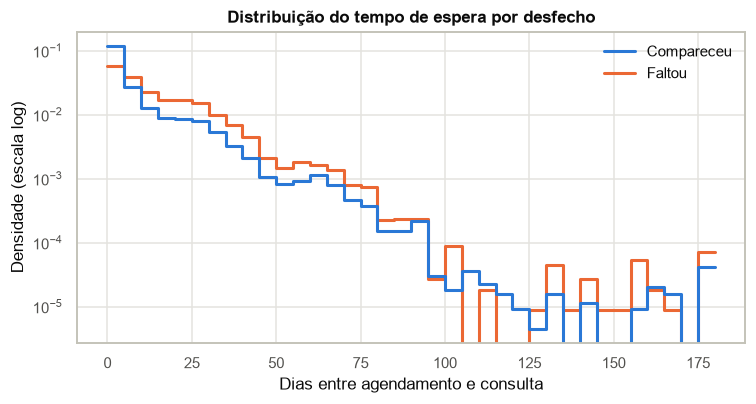

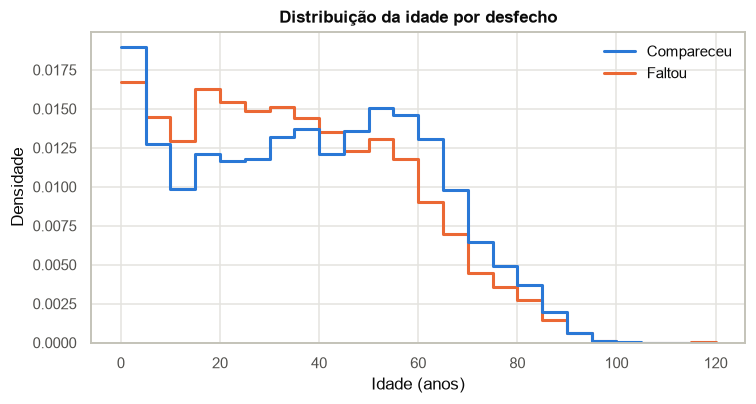

NoShow                   0        1
Age         count  88207.0  22314.0
            mean      37.8     34.3
            std       23.3     22.0
            min        0.0      0.0
            25%       18.0     16.0
            50%       38.0     33.0
            75%       56.0     51.0
            max      115.0    115.0
WaitingDays count  88207.0  22314.0
            mean       8.8     15.8
            std       14.6     16.6
            min        0.0      0.0
            25%        0.0      4.0
            50%        2.0     11.0
            75%       12.0     23.0
            max      179.0    179.0

In [14]:
graficos.grafico_histograma(df, "WaitingDays", "Distribuição do tempo de espera por desfecho",
                            "Dias entre agendamento e consulta", 180, escala_log=True)
plt.show()

graficos.grafico_histograma(df, "Age", "Distribuição da idade por desfecho", "Idade (anos)", 120)
plt.show()

df.groupby("NoShow")[["Age", "WaitingDays"]].describe().T.round(1)

## 5. Desenho experimental

### 5.1 Por que dividir por paciente

Antes de avaliar os modelos, foi testada a divisão aleatória comum, por linhas. O problema é que ela coloca consultas do mesmo paciente no treino e no teste ao mesmo tempo.

In [15]:
idx_treino_linhas, idx_teste_linhas = modelagem.dividir_por_linhas(df)
modelagem.medir_vazamento(df, idx_treino_linhas, idx_teste_linhas)

{'consultas_teste': 22105,
 'pacientes_teste': 18636,
 'pacientes_em_ambos': 10435,
 'consultas_teste_com_paciente_no_treino': 13260,
 'proporcao': 0.5998642840986202}

Nessa divisão, 60% das consultas do teste são de pacientes que o modelo já viu no treino. Para evitar isso foi usado o `StratifiedGroupKFold` com cinco dobras e `PatientId` como grupo. A primeira dobra virou o conjunto de teste e as outras quatro, o treino. O teste foi usado uma única vez, na avaliação final.

In [16]:
treino, teste = modelagem.dividir_por_paciente(df)
modelagem.resumo_divisao(treino, teste)

{'treino_consultas': 88416,
 'teste_consultas': 22105,
 'treino_pacientes': 49930,
 'teste_pacientes': 12368,
 'pacientes_em_ambos': 0,
 'taxa_falta_treino': 0.201897846543612,
 'taxa_falta_teste': 0.2019000226193169,
 'proporcao_teste': 0.20000723844337276}

### 5.2 Momento da previsão

No MediConnect, a previsão seria feita no agendamento, ou logo depois, para decidir quem recebe um lembrete reforçado. Nesse momento já se conhece sexo, idade, Bolsa Família, condições registradas, deficiência e o tempo de espera. O SMS vem depois, e é justamente a ação que o modelo deveria orientar. Além disso, a base não informa a data do envio. Por isso foram feitos dois experimentos:

- **Experimento A (principal):** sem `SMS_received`, com 8 atributos;
- **Experimento B (comparação):** com `SMS_received`, com 9 atributos, representando uma previsão feita depois do envio.

`PatientId` é usado só para formar os grupos e nunca entra como atributo.

In [17]:
print("Atributos do experimento A:", ATRIBUTOS_A)
print("Atributos do experimento B:", ATRIBUTOS_B)

Atributos do experimento A: ['Gender_M', 'Age', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'WaitingDays']
Atributos do experimento B: ['Gender_M', 'Age', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'WaitingDays', 'SMS_received']


## 6. Modelagem

Foram comparados quatro classificadores:

- **Referência:** sempre prevê a classe majoritária (comparecimento);
- **Regressão Logística:** atributos numéricos padronizados, `class_weight="balanced"` e busca do parâmetro `C`;
- **Árvore de Decisão:** sem padronização, `class_weight="balanced"` e busca de `max_depth` e `min_samples_leaf`;
- **MLP:** atributos numéricos padronizados, pesos por amostra balanceados (o `MLPClassifier` não tem `class_weight`), `early_stopping=True` e busca da arquitetura e de `alpha`.

Os hiperparâmetros foram escolhidos por busca em grade com cinco dobras agrupadas por paciente, só dentro do treino. O critério foi o F1-score da classe falta, e o limiar de decisão ficou em 0,5. A busca do MLP é a parte mais demorada e leva alguns minutos.

In [18]:
metricas_a, modelos_a, cv_a = modelagem.treinar_experimento("A", treino, teste, ATRIBUTOS_A)

  [A] Regressão Logística: {'C': 0.01} | F1 médio na validação = 0.399 (127.9 s)


  [A] Árvore de Decisão: {'max_depth': 3, 'min_samples_leaf': 50} | F1 médio na validação = 0.442 (100.6 s)


  [A] MLP: {'alpha': 0.001, 'hidden_layer_sizes': [64, 32]} | F1 médio na validação = 0.441 (618.8 s)


In [19]:
metricas_b, modelos_b, cv_b = modelagem.treinar_experimento("B", treino, teste, ATRIBUTOS_B)

  [B] Regressão Logística: {'C': 0.01} | F1 médio na validação = 0.406 (105.3 s)


  [B] Árvore de Decisão: {'max_depth': 12, 'min_samples_leaf': 200} | F1 médio na validação = 0.443 (159.5 s)


  [B] MLP: {'alpha': 0.01, 'hidden_layer_sizes': [64, 32]} | F1 médio na validação = 0.443 (227.2 s)


In [20]:
modelagem.tabela_hiperparametros(cv_a).style.format({"F1 médio na validação": "{:.3f}", "Desvio padrão": "{:.4f}"})

,Configuração selecionada,F1 médio na validação,Desvio padrão
Modelo,,,
Regressão Logística,C = 0.01,0.399,0.0054
Árvore de Decisão,max_depth = 3; min_samples_leaf = 50,0.442,0.0018
MLP,"alpha = 0.001; hidden_layer_sizes = [64, 32]",0.441,0.0019


## 7. Avaliação no conjunto de teste

### 7.1 Experimento A, sem SMS

In [21]:
formato = {c: "{:.3f}" for c in modelagem.COLUNAS_METRICAS}
metricas_a.style.format(formato)

,Acurácia,Precisão,Recall,F1-score,ROC-AUC,VN,FP,FN,VP
Referência (classe majoritária),0.798,0.000,0.000,0.000,0.500,17642,0,4463,0
Regressão Logística,0.691,0.330,0.515,0.403,0.668,12986,4656,2165,2298
Árvore de Decisão,0.591,0.305,0.799,0.441,0.715,9498,8144,895,3568
MLP,0.581,0.302,0.822,0.442,0.723,9163,8479,793,3670


A referência tem acurácia de 0,798, mas precisão, recall e F1 iguais a zero, porque nunca prevê falta. Isso confirma que a acurácia não serve para escolher o modelo.

O MLP teve o maior F1 (0,442), recall (0,822) e ROC-AUC (0,723). A Árvore de Decisão ficou praticamente empatada em F1 (0,441). A Regressão Logística teve precisão um pouco maior, mas recall bem menor. Os três modelos superaram a referência, o que apoia a H5.

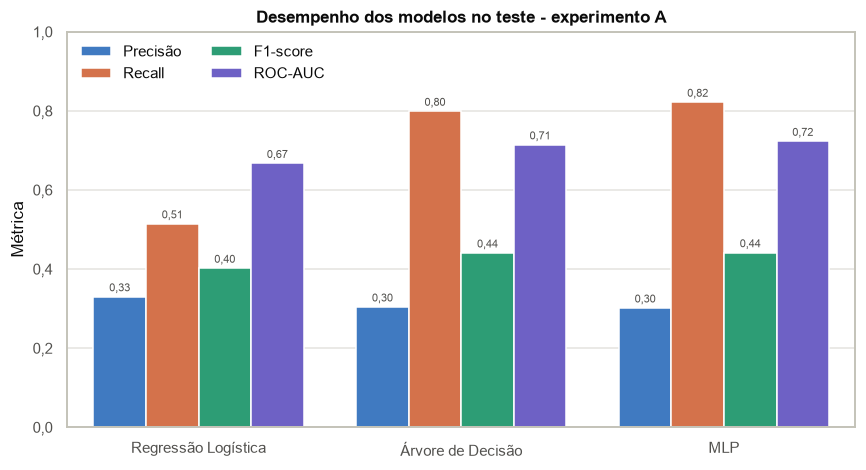

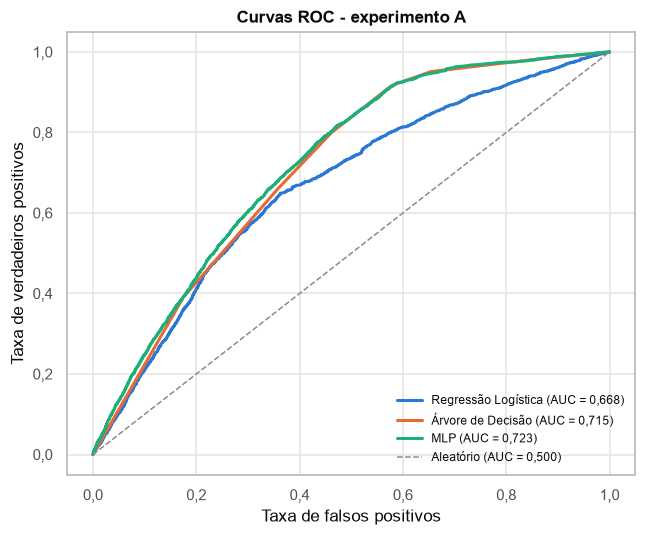

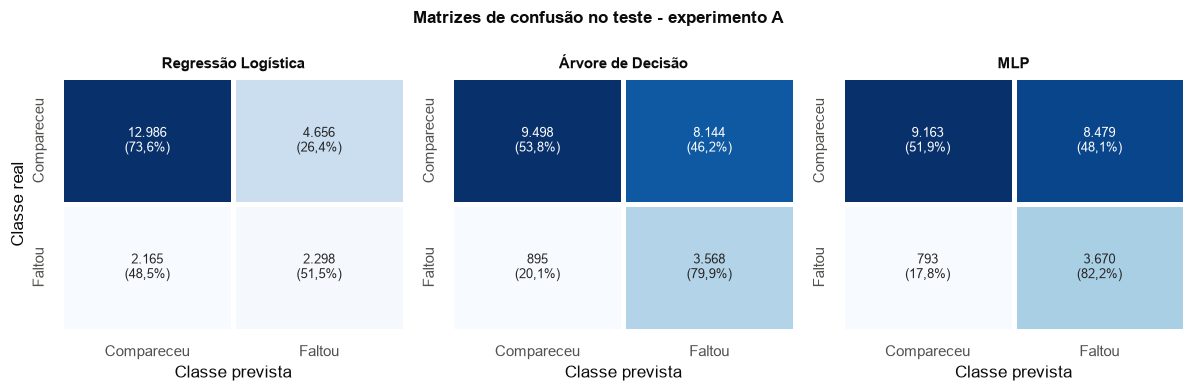

In [22]:
graficos.grafico_metricas(metricas_a)
plt.show()

graficos.grafico_roc(modelos_a, teste, ATRIBUTOS_A)
plt.show()

graficos.grafico_matrizes_confusao(metricas_a)
plt.show()

Na matriz de confusão do MLP, 82,2% das faltas foram identificadas, mas cerca de 70% dos alertas foram para consultas em que o paciente compareceu. Com tantos falsos positivos, o modelo só faz sentido para ações baratas, como um lembrete a mais, e nunca para decisões que restrinjam o atendimento.

### 7.2 Interpretação dos modelos

In [23]:
avaliacao.interpretar_modelos(modelos_a).round(3)

,Coeficiente RL (padronizado),Importância na árvore
WaitingDays,0.493,0.905
Age,-0.164,0.095
Handcap,-0.003,0.000
Gender_M,-0.017,0.000
Scholarship,0.224,0.000
Hipertension,-0.043,0.000
Diabetes,0.131,0.000
Alcoholism,0.156,0.000


In [24]:
print(avaliacao.regras_da_arvore(modelos_a))

|--- WaitingDays <= 0.5
|   |--- Age <= 21.5
|   |   |--- Age <= 6.5
|   |   |   |--- class: 0
|   |   |--- Age >  6.5
|   |   |   |--- class: 0
|   |--- Age >  21.5
|   |   |--- Age <= 56.5
|   |   |   |--- class: 0
|   |   |--- Age >  56.5
|   |   |   |--- class: 0
|--- WaitingDays >  0.5
|   |--- Age <= 49.5
|   |   |--- WaitingDays <= 9.5
|   |   |   |--- class: 1
|   |   |--- WaitingDays >  9.5
|   |   |   |--- class: 1
|   |--- Age >  49.5
|   |   |--- WaitingDays <= 7.5
|   |   |   |--- class: 0
|   |   |--- WaitingDays >  7.5
|   |   |   |--- class: 1



Na árvore, o tempo de espera responde por cerca de 90% da importância e a idade pelo restante; os outros atributos nem chegam a ser usados. A árvore escolhida tem profundidade 3: consultas do mesmo dia são classificadas como comparecimento, e nas demais o risco sobe com a espera e é menor para pessoas mais velhas. Na Regressão Logística o coeficiente de `WaitingDays` é positivo e o de `Age` é negativo, o que bate com a análise descritiva.

### 7.3 A diferença entre os modelos é maior que o acaso?

Para responder, foi feito um *bootstrap* pareado por paciente: 1.000 vezes, os pacientes do teste são sorteados com reposição (com todas as suas consultas) e os três modelos são avaliados na mesma amostra. Se o intervalo de 95% da diferença contém zero, a diferença não é conclusiva.

In [25]:
bootstrap = avaliacao.bootstrap_por_paciente(modelos_a, teste, ATRIBUTOS_A, metricas_a)
bootstrap.round(4)

,Comparação,Métrica,Diferença,IC 95% inferior,IC 95% superior,Conclusiva
0,MLP − Árvore de Decisão,F1-score,0.0007,-0.0030,0.0047,False
1,MLP − Árvore de Decisão,ROC-AUC,0.0089,0.0050,0.0128,True
2,MLP − Regressão Logística,F1-score,0.0393,0.0299,0.0487,True
3,MLP − Regressão Logística,ROC-AUC,0.0559,0.0490,0.0625,True
4,Árvore de Decisão − Regressão Logística,F1-score,0.0386,0.0297,0.0475,True
5,Árvore de Decisão − Regressão Logística,ROC-AUC,0.0471,0.0397,0.0539,True


Entre o MLP e a Árvore, a diferença de F1 não é conclusiva, porque o intervalo inclui zero. O MLP tem ROC-AUC um pouco maior, mas isso não muda o empate prático em F1. Os dois ficam acima da Regressão Logística com intervalos que não incluem zero.

### 7.4 Experimento B e análise de sensibilidade

In [26]:
metricas_b.style.format(formato)

,Acurácia,Precisão,Recall,F1-score,ROC-AUC,VN,FP,FN,VP
Referência (classe majoritária),0.798,0.000,0.000,0.000,0.500,17642,0,4463,0
Regressão Logística,0.672,0.322,0.564,0.410,0.670,12346,5296,1947,2516
Árvore de Decisão,0.586,0.301,0.797,0.438,0.721,9398,8244,905,3558
MLP,0.597,0.307,0.789,0.442,0.727,9680,7962,942,3521


Com o SMS, as métricas quase não mudam. Isso não mostra que o SMS reduza as faltas, e como o momento e a regra de envio não são conhecidos, essa variável fica só como comparação.

A análise de sensibilidade retreina os modelos do Experimento A, com os mesmos hiperparâmetros, na divisão por linhas, para comparar com a divisão por paciente. Ela não foi usada para escolher o modelo.

In [27]:
avaliacao.sensibilidade_por_linhas(df, modelos_a, idx_treino_linhas, idx_teste_linhas,
                                   ATRIBUTOS_A, metricas_a).round(3)

,F1 (linhas),F1 (paciente),ROC-AUC (linhas),ROC-AUC (paciente)
Regressão Logística,0.398,0.403,0.665,0.668
Árvore de Decisão,0.440,0.441,0.710,0.715
MLP,0.440,0.442,0.719,0.723


Nesta base, os resultados das duas divisões ficaram próximos. Mesmo assim, a divisão por paciente é o protocolo correto para medir como o modelo se sai com pacientes que ele nunca viu.

## 8. Considerações finais

O tempo de espera foi o sinal mais forte para separar consultas com maior e menor chance de falta, e a idade acrescenta alguma informação. Os demais atributos têm associação fraca. Nos modelos sem SMS, o MLP e a Árvore de Decisão ficaram empatados em F1 (cerca de 0,44), com recall alto e precisão perto de 0,30.

Esses modelos podem apoiar ações de baixo custo, como lembretes e confirmações, mas não estão prontos para uso real. A base cobre cerca de seis semanas de 2016 em Vitória, a divisão não foi temporal, o limiar de 0,5 não foi ajustado ao custo de cada erro e as probabilidades não foram calibradas. Qualquer uso com dados reais de pacientes também depende de análise jurídica e de proteção compatível com a LGPD.

A discussão completa, com as referências, está no artigo em `docs/`.